### **Analysis of TF-gene Interactions**
##### **Simplify Graph**

Prereqs: use build-grn notebook to create a graph in ../results/networks/ \
Import graphml file:

In [9]:
import networkx as nx

# Get network
G_original = nx.read_graphml("../results/networks/2026-08-04_big-grn-with-model.graphml")
print(G_original)

G_original_tf_nodes = [n for n, d in G_original.nodes(data=True) if d.get("node_type") == "TF"]
print(len(G_original_tf_nodes))
G_original_gene_nodes = [n for n, d in G_original.nodes(data=True) if d.get("node_type") == "gene"]
print(len(G_original_gene_nodes))

print(G_original_tf_nodes)

DiGraph with 13708 nodes and 185488 edges
57
13651
['ENCFF612MNU_ZNF511', 'ENCFF387KML_ETV6', 'ENCFF455TXX_ZNF546', 'ENCFF701DTE_TP53', 'ENCFF335VPW_POGK', 'ENCFF422MYG_ZNF513', 'ENCFF542SUS_REL', 'ENCFF521AKL_EZH2', 'ENCFF748PEB_ZCCHC11', 'ENCFF405UGF_SKI', 'ENCFF603NUV_E2F8', 'ENCFF765MRZ_LRRFIP1', 'ENCFF171VVS_GTF2F1', 'ENCFF318CUZ_FOXO4', 'ENCFF582HAZ_LIN54', 'ENCFF504CCV_CCAR2', 'ENCFF959TJF_ZNF296', 'ENCFF463GXC_ATF6', 'ENCFF612NCS_ZNF256', 'ENCFF981WJF_ZMAT3', 'ENCFF104XLA_ZNF234', 'ENCFF732NHA_E2F5', 'ENCFF745YRF_NONO', 'ENCFF889SKN_TAF15', 'ENCFF070QDA_ZNF639', 'ENCFF517FAL_HMG20B', 'ENCFF457BJI_RBM22', 'ENCFF567JIZ_PPARG', 'ENCFF305SZV_XRCC5', 'ENCFF670IOD_ZNF761', 'ENCFF682NJA_FUS', 'ENCFF055HMB_HNRNPH1', 'ENCFF052BXQ_RNF2', 'ENCFF321UQK_SRSF1', 'ENCFF896PGF_ZSCAN29', 'ENCFF458FBS_ZNF786', 'ENCFF490TYP_HMGA1', 'ENCFF359DKY_GRHL1', 'ENCFF034RYJ_ZNF629', 'ENCFF882GQF_ZNF589', 'ENCFF796LVD_RBM39', 'ENCFF935NRC_SOX13', 'ENCFF254ZSQ_CSRNP2', 'ENCFF057MJF_U2AF1', 'ENCFF510QJE_MBD1

#### **Simplify Graph**
- Gene nodes are named by just the name of the protein they encode, and TF nodes are named with the Encode ID + '_' + name
- So we can rename the TF nodes to just what comes after the underscore
- Then TF nodes and their corresponding gene nodes become one node

Graphs
1. G_original: straight from output of model-and-build-graph file. Has 13708 nodes and 185488 edges. Gene nodes and TF nodes are seperate.
2. G_full: TF nodes renamed so they combine with the gene nodes that encode for them. 
3. G: only nodes that correspond to both a TF and a gene are kept. 

In [25]:
def strip_before_underscore(name):
    # keep everything AFTER the first underscore; if no underscore, keep as-is
    return name.split("_", 1)[1] if "_" in name else name

# manual merge: build a new graph, aggregating (here: max weight) when
# multiple old edges collapse onto the same (new_source, new_target) pair
G_full = nx.DiGraph()

# 8/11 Replaced
#for node, data in G_original.nodes(data=True):
#    G_full.add_node(strip_before_underscore(node), **data)

for node, data in G_original.nodes(data=True):
    stripped = strip_before_underscore(node)
    if G_full.has_node(stripped):
        existing = G_full.nodes[stripped]
        # preserve TF status if either version is a TF
        if existing.get("node_type") == "TF" or data.get("node_type") == "TF":
            existing["node_type"] = "TF"
        # merge/keep other attributes as needed
    else:
        G_full.add_node(stripped, **data)

#G_original_tf_nodes_parsed = []
#for node in G_original_tf_nodes:
#    G_original_tf_nodes_parsed.add_node()

for u, v, data in G_original.edges(data=True):
    new_u, new_v = strip_before_underscore(u), strip_before_underscore(v)
    if G_full.has_edge(new_u, new_v):
        # conflict: combine instead of overwrite -- here, keep the max weight
        G_full[new_u][new_v]["weight"] = max(G_full[new_u][new_v]["weight"], data["weight"])
    else:
        G_full.add_edge(new_u, new_v, **data)                # somewhere here we lose 5 nodes: {'ISX', 'FOXO4', 'ZNF511', 'TP53', 'ETV6'}

print("Nodes of G_full:", list(G_full.nodes()))

print(G_original)
print(G_full)
# There are the same number of edges (correct) and 53 fewer nodes
# - expected 57 but maybe the genes that encode 4 of the TFs were not present in the network
G_full_tf_nodes = [n for n, d in G_full.nodes(data=True) if d.get("node_type") == "TF"]
print(len(G_full_tf_nodes))
G_full_gene_nodes = [n for n, d in G_full.nodes(data=True) if d.get("node_type") == "gene"]
print(len(G_full_gene_nodes))

Nodes of G_full: ['ZNF511', 'NPAS4', 'XKR7', 'INSM2', 'RANBP3', 'RAB37', 'CELSR3', 'FAM24A', 'HTR5A', 'IRF9', 'STAT3', 'SLC7A6OS', 'PCK2', 'CPLX2', 'NME1-NME2', 'STAT1', 'SNRPB', 'GLRA1', 'LEMD3', 'MAST1', 'TRIB3', 'TMEM181', 'ZMYND8', 'APOB', 'CDIP1', 'STK25', 'NEURL2', 'CHGB', 'KATNA1', 'PRMT5', 'PIK3R3', 'BARHL1', 'MRPS23', 'NFKBIA', 'POLR3E', 'PRPSAP1', 'SPOP', 'RBM39', 'RBM28', 'RABGGTA', 'KDM3A', 'CPPED1', 'RBL1', 'IPO4', 'SCFD1', 'RPL27', 'SRP54', 'GDAP1L1', 'PRB2', 'RNF130', 'SLC25A10', 'MOB4', 'TASOR2', 'MDP1', 'TMEM242', 'GMEB2', 'CNBD2', 'SNRPB2', 'ORAI3', 'GCFC2', 'RBM12', 'ZCCHC3', 'CDK5RAP1', 'PSMD3', 'DPY19L4', 'PTPRS', 'AURKA', 'NDUFAB1', 'SLC39A3', 'PMVK', 'CKLF-CMTM1', 'SMG8', 'NTSR2', 'RFC1', 'DCPH1', 'KDM1A', 'PGRMC2', 'AARS2', 'MTERF4', 'VGF', 'RPS7', 'ENPP3', 'ABCA3', 'DHX8', 'UQCC1', 'EIF4E2', 'CHRM4', 'DDX1', 'PTPRN', 'DHRS4', 'EAPP', 'ARL6IP1', 'TTI2', 'ENSG00000285043', 'TOMM34', 'KDM8', 'PET117', 'SYS1-DBNDD2', 'GOPC', 'MTF2', 'HEATR5A', 'ENSG00000288678', 'I

In [11]:
# 8/10 Are any of the nodes in G_original_tf_nodes duplicates? This is a dict, so just strip each entry
G_original_tf_nodes_parsed = []
for entry in G_original_tf_nodes:
    G_original_tf_nodes_parsed.append(strip_before_underscore(entry))
import numpy as np
print(len(G_original_tf_nodes_parsed))
print(len(np.unique(G_original_tf_nodes_parsed)))
print(len(set(G_original_tf_nodes_parsed)))

57
57
57


In [13]:
# 8/10 No there were no duplicates. Find names of those TFs

In [ ]:
# G will only have nodes that are associated with TFs
G = G_full.copy()

# for each gene node in G_full, remove that from G
#gene_nodes = [n for n, d in G_full.nodes(data=True) if d.get("node_type") == "gene"]
#G.remove_nodes_from(gene_nodes)

tf_nodes = [n for n, d in G_full.nodes(data=True) if d.get("node_type") == "TF"]
non_tf_nodes = [n for n in G_full.nodes() if n not in tf_nodes]
G.remove_nodes_from(non_tf_nodes)

print(G)
G_tf_nodes = [n for n, d in G.nodes(data=True) if d.get("node_type") == "TF"]
print(len(G_tf_nodes)) # 52 -------- now 57 as of 8/11
G_gene_nodes = [n for n, d in G.nodes(data=True) if d.get("node_type") == "gene"]
print(len(G_gene_nodes)) # 0


DiGraph with 57 nodes and 936 edges
57
0


In [ ]:
# 8/11 Find names of TFs that were removed
print(set(G_original_tf_nodes_parsed) - set(G_tf_nodes)) # gave 5 names, now blank as of 8/11 (2pm)

set()


**Save G_full and G**

In [28]:
output_path = "../results/networks/DATE_grn-combined"
nx.write_graphml(G_full, output_path + "-with-spokes.graphml")
nx.write_graphml(G, output_path + "-TF-nodes-only.graphml")


# **<span style="color: red">---------------------------------------------------------------------------</span>**

## **Analysis**
**Things to Look At**
1. Degree
2. Centrality
3. Connected Components
4. Feed-forward Loops
5. Visualization


In [39]:
import networkx as nx
#G = nx.read_graphml("../results/networks/2026-08-06_grn-combined-TF-nodes-only.graphml")
G = nx.read_graphml("../results/networks/2026-08-11_grn-combined-TF-nodes-only.graphml")
print(G)

DiGraph with 57 nodes and 936 edges


#### **1. Degree**
- **Out-degree**: how many genes a node regulates
- **In-degree**: how many TFs regulate a node

In [29]:
# out and in degrees
out_degrees = dict(G.out_degree())
in_degrees = dict(G.in_degree())

# print top 3 nodes by each degree type, sorted highest first
sorted_out_degrees = sorted(out_degrees.items(), key=lambda x: x[1], reverse=True)
for node, deg in sorted_out_degrees[0:3]:
    print(f"Node {node} regulates {deg} nodes")

sorted_in_degrees = sorted(in_degrees.items(), key=lambda x: x[1], reverse=True)
for node, deg in sorted_in_degrees[0:3]:
    print(f"Node {node} is regulated by {deg} nodes")

Node LIN54 regulates 45 nodes
Node E2F8 regulates 41 nodes
Node RBM39 regulates 40 nodes
Node RBM39 is regulated by 44 nodes
Node FUS is regulated by 42 nodes
Node CCAR2 is regulated by 30 nodes


In [30]:
import numpy as np
avg_out_degree = np.mean(list(out_degrees.values()))
avg_in_degree = np.mean(list(in_degrees.values()))

print("Average out-degree:", avg_out_degree)
print("Average in-degree:", avg_in_degree)

Average out-degree: 16.42105263157895
Average in-degree: 16.42105263157895


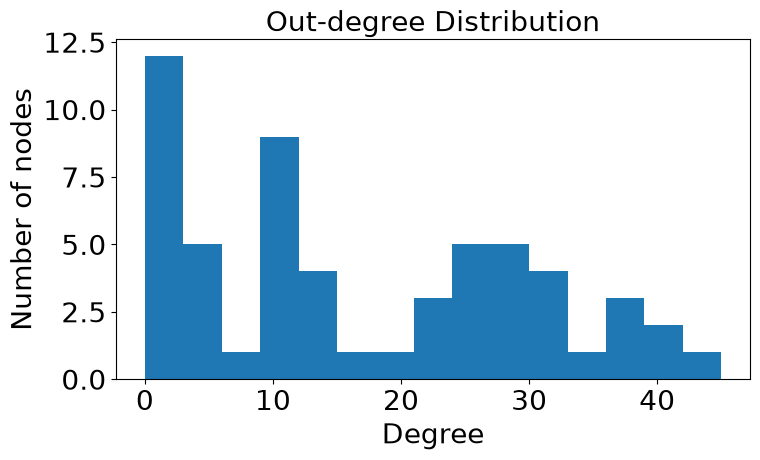

In [48]:
# 8/10 Degree distribution for poster
import matplotlib.pyplot as plt

# 8/11 Make font bigger
# Set global font size (e.g., 14pt)
plt.rcParams['font.size'] = 20
# Optional: Increase title and label sizes specifically if needed
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20

plt.figure(figsize=(8, 5))
plt.hist(out_degrees.values(), bins=15, alpha=1, label="Out-degree")
plt.xlabel("Degree")
plt.ylabel("Number of nodes")
plt.title("Out-degree Distribution")
plt.tight_layout()
plt.show()

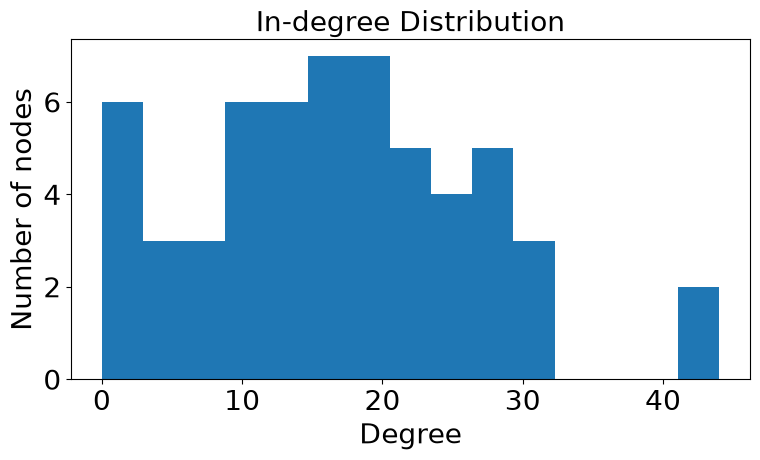

In [49]:
plt.figure(figsize=(8, 5))
plt.hist(in_degrees.values(), bins=15, alpha=1, label="In-degree") # was originally 20
plt.xlabel("Degree")
plt.ylabel("Number of nodes")
plt.title("In-degree Distribution")
plt.tight_layout()
plt.show()

#### **2. Centrality**
- **Betweenness centrality**: how often a node lies on the shortest path between other nodes
  (bottlenecks/bridges between regulatory modules)
- **PageRank**: importance based on being pointed to by *other important* nodes

In [33]:
# betweenness and page rank
betweenness = nx.betweenness_centrality(G)
pagerank = nx.pagerank(G)

# print top 3 nodes by betweenness centrality (with scores)
top_centrality = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)
for node, score in top_centrality[0:3]: # elements of top_centrality are pairs with the first element being the node and the second the score
    print(f'Node {node}: score {score}')

# print top 3 nodes by PageRank (with scores)
top_pagerank = sorted(pagerank.items(), key=lambda x: x[1], reverse=True)
for node, score in top_pagerank[:3]:
    print(f'Node {node}: pagerank {score:.3f}')


Node RBM39: score 0.1389367368584788
Node LIN54: score 0.06088464989860921
Node FUS: score 0.058294793121395155
Node RBM39: pagerank 0.082
Node FUS: pagerank 0.063
Node ZFAT: pagerank 0.061


#### **3. Connected Components**
- **Weakly connected components**: ignore edge direction
- **Strongly connected components**: respect edge direction - a strongly connected component with more than 1 node means there's a feedback loop

In [50]:
weak_components = list(nx.weakly_connected_components(G))

# list of strongly connected components with more than 1 node
strong_components = []
for c in nx.strongly_connected_components(G):
    if len(c) > 1: 
        strong_components.append(c)

print(f"Number of weakly connected components: {len(weak_components)}")

print(f"Number of strongly connected components (feedback loops): {len(strong_components)}")
print(f"strong_components: {strong_components}")
print(f"Length of first component: {len(strong_components[0])}")


Number of weakly connected components: 1
Number of strongly connected components (feedback loops): 1
strong_components: [{'ZNF296', 'LIN54', 'ZNF513', 'PAXIP1', 'ZNF629', 'CCAR2', 'ATF6', 'ZBTB43', 'GTF2F1', 'ETV6', 'ZMAT3', 'ZNF639', 'NONO', 'ZNF234', 'E2F8', 'ZNF407', 'POGK', 'ZSCAN29', 'SRSF4', 'SRSF1', 'DNMT3B', 'ZFAT', 'SKI', 'GTF3A', 'ZNF697', 'ISX', 'LRRFIP1', 'ZNF256', 'EZH2', 'XRCC5', 'RNF2', 'HMG20B', 'ZNF511', 'REL', 'RBM39', 'ZNF786', 'AGO2', 'ZNF850', 'MBD1', 'E2F5', 'FUS', 'ZNF589', 'PPARG', 'TAF15', 'TP53', 'ZNF761'}]
Length of first component: 46


#### **4. Motifs: Loops**
The **feed-forward loop** (FFL) is the most-studied network motif in gene regulation

In [35]:
def find_feed_forward_loops(G):
    ffls = []
    # for every node 'a', look at its successors 'b', for each of those, look at its successors 'c'
    # if 'a' also has a direct edge to 'c', that's a feed-forward loop!
    for a in G.nodes():
        for b in G.successors(a):
            if b==a: continue           # added 8/7 (without these 2 lines, got 9022 loops)
            for c in G.successors(b):
                if c in (a,b): continue # added 8/7 (with them, got 7830, same as other function below)
                if G.has_edge(a,c)==True: ffls.append((a,b,c))
    return ffls

ffls = find_feed_forward_loops(G)
print(f"Feed-forward loops found: {len(ffls)}")
print(f"Showing 10 of {len(ffls)}")
for a, b, c in ffls[0:10]:
    print(f"  {a} -> {b} -> {c}, and {a} -> {c} directly")


Feed-forward loops found: 8900
Showing 10 of 8900
  ZNF511 -> RBM39 -> FUS, and ZNF511 -> FUS directly
  ZNF511 -> RBM39 -> CSRNP2, and ZNF511 -> CSRNP2 directly
  ZNF511 -> RBM39 -> ZNF629, and ZNF511 -> ZNF629 directly
  ZNF511 -> RBM39 -> TAF15, and ZNF511 -> TAF15 directly
  ZNF511 -> RBM39 -> SRSF4, and ZNF511 -> SRSF4 directly
  ZNF511 -> RBM39 -> ZNF786, and ZNF511 -> ZNF786 directly
  ZNF511 -> RBM39 -> ZFAT, and ZNF511 -> ZFAT directly
  ZNF511 -> RBM39 -> MBD1, and ZNF511 -> MBD1 directly
  ZNF511 -> RBM39 -> AGO2, and ZNF511 -> AGO2 directly
  ZNF511 -> RBM39 -> POGK, and ZNF511 -> POGK directly


#### **5. Visualize**
Node size scaled by out-degree

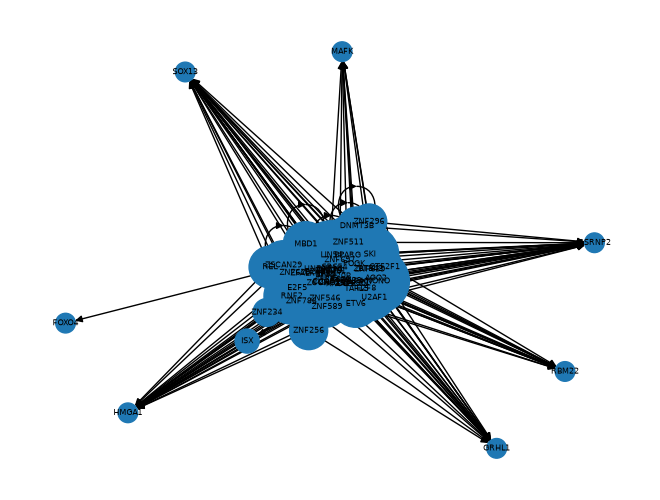

In [36]:
import matplotlib as plt
# create a layout for the nodes
pos = nx.spring_layout(G, seed=44) # don't do this for big graphs, it is O(n^2)

# scale node sizes using out_degrees (base size + multiplier * degree)
node_sizes = [200 + 50 * out_degrees.get(n,0) for n in G.nodes()]

# draw the graph
nx.draw(
    G, pos, with_labels=True, node_size=node_sizes,
    #node_color="lightblue", edge_color="gray",
    arrows=True, arrowsize=10, font_size=6
)
#plt.title("TF-Gene Regulatory Network")
#plt.show()


**Questions**
- Does the degree distribution look scale-free (few hubs, many low-degree nodes)? No
- Do the highest-betweenness nodes match known "bottleneck" regulators in the literature?
- How many feed-forward loops do you find, and do they involve known co-regulatory pairs?
- Is the network one connected component, or fragmented? What might explain that? It is one connected component - this makes sense.


# **<span style="color: red">---------------------------------------------------------------------------</span>**

#### **6. Reciprocity**
What fraction of edges are mutual?

In [37]:
import random
import matplotlib.pyplot as plt

reciprocity = nx.overall_reciprocity(G)
reciprocity

0.33974358974358976

#### **7. Assortativity**
Assortativity — do high-degree TFs preferentially regulate other high-degree TFs (assortative), or do hubs mostly connect to low-degree TFs (disassortative)?

Correlation between out-degree of source and in-degree of target across edges.\
Negative = hubs tend to regulate low-degree TFs (common in biological
regulatory networks). \
Positive = hubs cluster together.

In [38]:
assortativity = nx.degree_assortativity_coefficient(G, x="out", y="in")
assortativity

-0.2613918781446843

#### **8. Robustness: targeted vs. random node removal**

Remove nodes one at a time and track the size of the largest weakly connected
component. Targeted removal takes the highest-centrality node each time
(recomputing centrality after every removal, since removing a hub changes
everyone else's centrality). Random removal is averaged over several trials.
A big gap between the two curves means the network is hub-dependent/fragile.

In [9]:
def giant_component_fraction(H, n_original):
    if H.number_of_nodes() == 0:
        return 0.0
    largest_wcc = max(nx.weakly_connected_components(H), key=len)
    return len(largest_wcc) / n_original

def targeted_removal_curve(G, centrality_func=nx.degree_centrality):
    H = G.copy()
    n_original = G.number_of_nodes()
    sizes = [giant_component_fraction(H, n_original)]
    while H.number_of_nodes() > 0:
        centrality = centrality_func(H)
        node_to_remove = max(centrality, key=centrality.get)
        H.remove_node(node_to_remove)
        sizes.append(giant_component_fraction(H, n_original))
    return sizes

def random_removal_curve(G, n_trials=20):
    n_original = G.number_of_nodes()
    all_trials = []
    for _ in range(n_trials):
        H = G.copy()
        nodes = list(H.nodes())
        random.shuffle(nodes)
        sizes = [giant_component_fraction(H, n_original)]
        for node in nodes:
            H.remove_node(node)
            sizes.append(giant_component_fraction(H, n_original))
        all_trials.append(sizes)
    return [sum(trial[i] for trial in all_trials) / n_trials for i in range(len(all_trials[0]))]

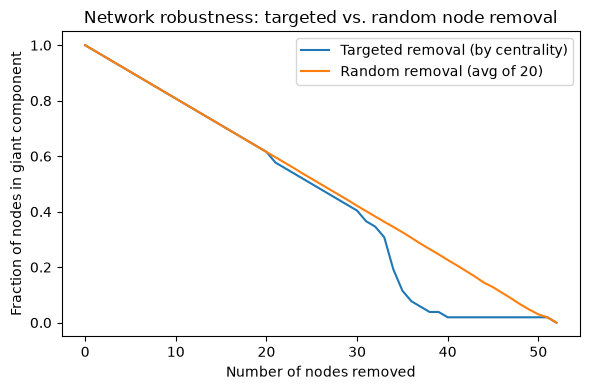

In [10]:
targeted = targeted_removal_curve(G)
random_avg = random_removal_curve(G, n_trials=20)

plt.figure(figsize=(6, 4))
plt.plot(targeted, label="Targeted removal (by centrality)")
plt.plot(random_avg, label="Random removal (avg of 20)")
plt.xlabel("Number of nodes removed")
plt.ylabel("Fraction of nodes in giant component")
plt.title("Network robustness: targeted vs. random node removal")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
def count_ffls(G):
    count = 0
    for a in G.nodes():
        for b in G.successors(a):
            if b == a:
                continue
            for c in G.successors(b):
                if c in (a, b):
                    continue
                if G.has_edge(a, c):
                    count += 1
    return count

ffl_count = count_ffls(G)
ffl_count

7830

## 9. Statistical significance vs. a degree-preserving null model

`nx.directed_edge_swap` randomizes edges while keeping every node's in-degree
and out-degree exactly the same as in `G`.

Note: `nx.double_edge_swap` does NOT work on directed graphs -- it raises an
error. If that error is caught too broadly, it silently leaves the graph
completely unshuffled, which would make every "null model" identical to `G`.
`directed_edge_swap` is the correct function for a DiGraph.

In [22]:
def null_model(G, n_swaps_multiplier=5, max_tries_multiplier=20, seed=None):
    H = G.copy()
    n_edges = H.number_of_edges()
    try:
        nx.directed_edge_swap(
            H,
            nswap=n_edges * n_swaps_multiplier,
            max_tries=n_edges * max_tries_multiplier,
            seed=seed,
        )
        completed = True
    except nx.NetworkXAlgorithmError:
        completed = False
    return H, completed


def null_model_pvalue(G, metric_func, n_null_models=100, seed=None):
    observed = metric_func(G)
    null_values = []
    n_incomplete = 0
    for i in range(n_null_models):
        H, completed = null_model(G, seed=(seed + i if seed is not None else None))
        if not completed:
            n_incomplete += 1
        null_values.append(metric_func(H))

    if n_incomplete:
        print(f"Note: {n_incomplete}/{n_null_models} null models had incomplete swaps "
              f"(graph may be small/dense) — still usable, just less thoroughly randomized.")

    p_value = sum(v >= observed for v in null_values) / n_null_models
    return observed, null_values, p_value

In [23]:
%time H_test = null_model(G, seed=0)

CPU times: user 60.4 ms, sys: 20 μs, total: 60.4 ms
Wall time: 60.9 ms


In [24]:
observed_ffl, null_ffl, p_ffl = null_model_pvalue(G, count_ffls, n_null_models=50, seed=42)
print(f"FFL count: observed={observed_ffl}, null mean={sum(null_ffl)/len(null_ffl):.1f}, p={p_ffl:.3f}")

observed_recip, null_recip, p_recip = null_model_pvalue(G, nx.overall_reciprocity, n_null_models=50, seed=42)
print(f"Reciprocity: observed={observed_recip:.3f}, null mean={sum(null_recip)/len(null_recip):.3f}, p={p_recip:.3f}")

Note: 50/50 null models had incomplete swaps (graph may be small/dense) — still usable, just less thoroughly randomized.
FFL count: observed=7830, null mean=7822.2, p=0.500
Note: 50/50 null models had incomplete swaps (graph may be small/dense) — still usable, just less thoroughly randomized.
Reciprocity: observed=0.341, null mean=0.329, p=0.180
